# Predicting Medical Insurance Charges with Regression
### Keaton Ludwig

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization style
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

### Load Dataset

In [2]:
# Load the insurance dataset
df = pd.read_csv("insurance.csv")

# Display the first five rows
display(df.head())

# Display dataset dimensions
print(f"Dataset contains {df.shape[0]:,} observations and {df.shape[1]} variables.")

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


Dataset contains 1,338 observations and 7 variables.


### Verify Data Quality

In [3]:
# Check data types
print("Data Types:")
display(df.dtypes)

# Check missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Summary statistics
print("\nSummary Statistics:")
display(df.describe())

Data Types:


age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


Missing Values:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Duplicate Rows: 1

Summary Statistics:


,age,bmi,children,charges
count,"1,338.00","1,338.00","1,338.00","1,338.00"
mean,39.21,30.66,1.09,"13,270.42"
std,14.05,6.10,1.21,"12,110.01"
min,18.00,15.96,0.00,"1,121.87"
25%,27.00,26.30,0.00,"4,740.29"
50%,39.00,30.40,1.00,"9,382.03"
75%,51.00,34.69,2.00,"16,639.91"
max,64.00,53.13,5.00,"63,770.43"


### Define Predictor and Target Variables

In [4]:
# Target variable
target = "charges"

# Predictor variables
X = df.drop(columns=[target])
y = df[target]

print("Predictor variables:")
print(list(X.columns))

print("\nTarget variable:")
print(target)

Predictor variables:
['age', 'sex', 'bmi', 'children', 'smoker', 'region']

Target variable:
charges


### Identify Numerical/Categorical Variables

In [5]:
# Identify numerical variables
numeric_features = [
    "age",
    "bmi",
    "children"
]

# Identify categorical variables
categorical_features = [
    "sex",
    "smoker",
    "region"
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'bmi', 'children']

Categorical features:
['sex', 'smoker', 'region']


### Create Train-Test Split (80/20)

In [6]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 1070
Testing observations: 268


### Begin Preprocessing Pipeline

In [7]:
# Preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

### Multiple Linear Regression Model

In [8]:
# Create Multiple Linear Regression pipeline
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model
linear_model.fit(X_train, y_train)

# Generate predictions
y_pred_linear = linear_model.predict(X_test)

### Evaluate Model

In [9]:
# Calculate evaluation metrics
linear_r2 = r2_score(y_test, y_pred_linear)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

linear_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)

print("Multiple Linear Regression Performance")
print("---------------------------------------")
print(f"R²:   {linear_r2:.4f}")
print(f"RMSE: ${linear_rmse:,.2f}")
print(f"MAE:  ${linear_mae:,.2f}")

Multiple Linear Regression Performance
---------------------------------------
R²:   0.7836
RMSE: $5,796.28
MAE:  $4,181.19


### Random Forest Regression Model

In [10]:
# Create Random Forest Regression pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=500,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

### Evaluate Model

In [11]:
# Calculate evaluation metrics
rf_r2 = r2_score(y_test, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

rf_mae = mean_absolute_error(
    y_test,
    y_pred_rf
)

print("Random Forest Regression Performance")
print("------------------------------------")
print(f"R²:   {rf_r2:.4f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"MAE:  ${rf_mae:,.2f}")

Random Forest Regression Performance
------------------------------------
R²:   0.8635
RMSE: $4,603.40
MAE:  $2,560.21


### Model Comparison

In [12]:
model_results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Random Forest Regression"
    ],
    "R²": [
        linear_r2,
        rf_r2
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ]
})

display(model_results)

,Model,R²,RMSE,MAE
0,Multiple Linear Regression,0.78,"5,796.28","4,181.19"
1,Random Forest Regression,0.86,"4,603.40","2,560.21"


### Actual vs. Predicted: Linear Regression

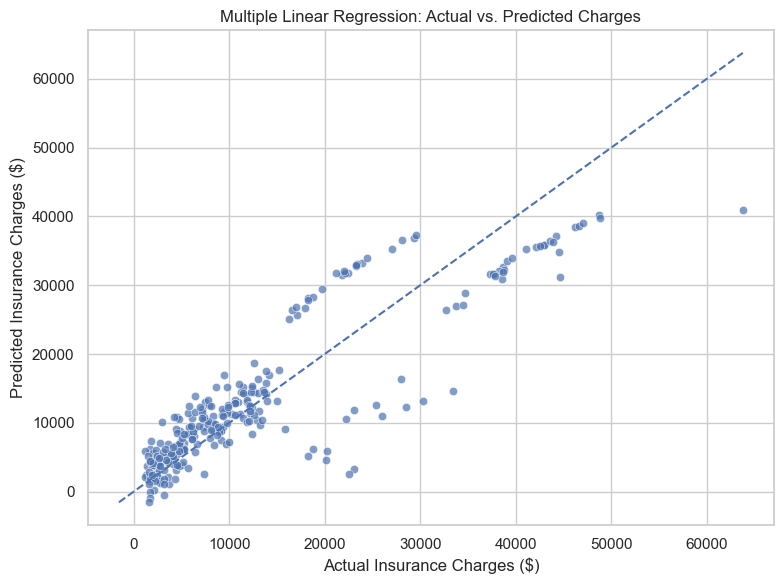

In [14]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_linear,
    alpha=0.7
)

# Perfect prediction line
min_value = min(y_test.min(), y_pred_linear.min())
max_value = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Multiple Linear Regression: Actual vs. Predicted Charges")
plt.xlabel("Actual Insurance Charges ($)")
plt.ylabel("Predicted Insurance Charges ($)")

plt.tight_layout()
plt.show()

### Actual vs. Predicted: Random Forest

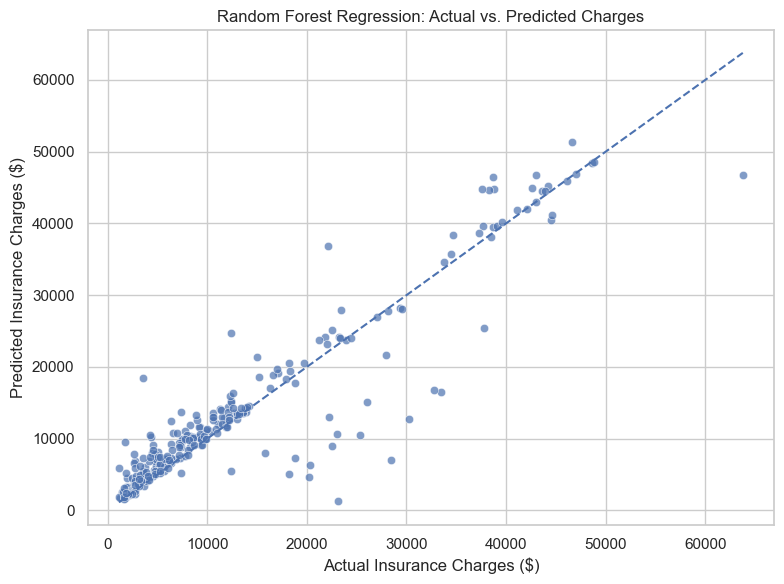

In [15]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_rf,
    alpha=0.7
)

min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Random Forest Regression: Actual vs. Predicted Charges")
plt.xlabel("Actual Insurance Charges ($)")
plt.ylabel("Predicted Insurance Charges ($)")

plt.tight_layout()
plt.show()

### Residual Analysis

In [16]:
linear_residuals = y_test - y_pred_linear
rf_residuals = y_test - y_pred_rf

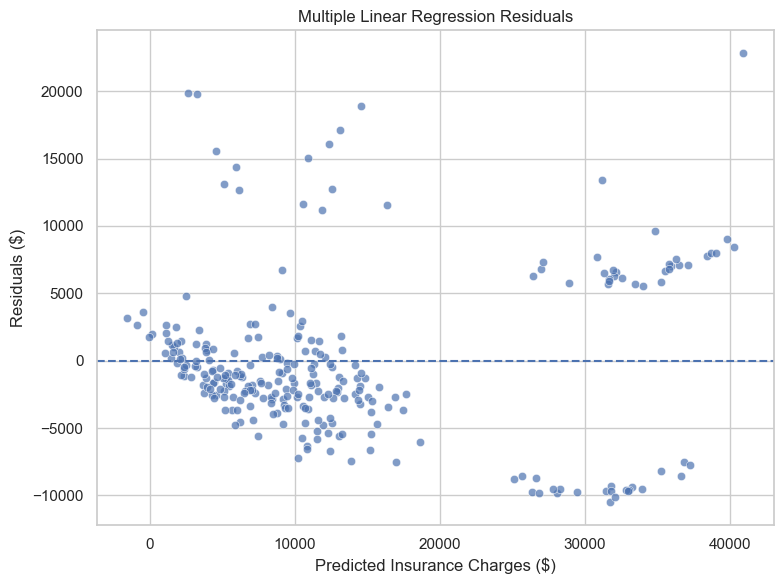

In [17]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_pred_linear,
    y=linear_residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Multiple Linear Regression Residuals")
plt.xlabel("Predicted Insurance Charges ($)")
plt.ylabel("Residuals ($)")

plt.tight_layout()
plt.show()

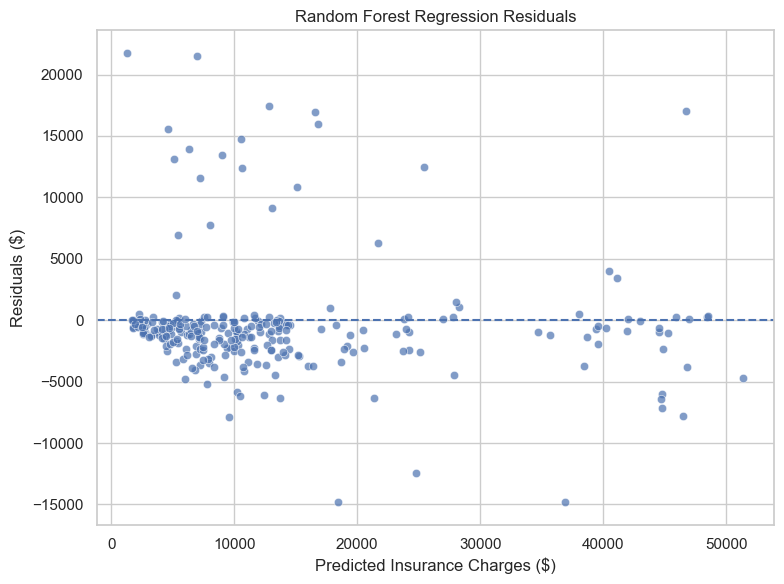

In [18]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_pred_rf,
    y=rf_residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Random Forest Regression Residuals")
plt.xlabel("Predicted Insurance Charges ($)")
plt.ylabel("Residuals ($)")

plt.tight_layout()
plt.show()

### Feature Importance: Random Forest

In [19]:
# Get encoded feature names
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance values
importances = (
    random_forest_model
    .named_steps["model"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
)

display(feature_importance)

,Feature,Importance
1,categorical__smoker_yes,0.61
6,numeric__bmi,0.22
5,numeric__age,0.13
7,numeric__children,0.02
0,categorical__sex_male,0.01
2,categorical__region_northwest,0.01
3,categorical__region_southeast,0.01
4,categorical__region_southwest,0.00


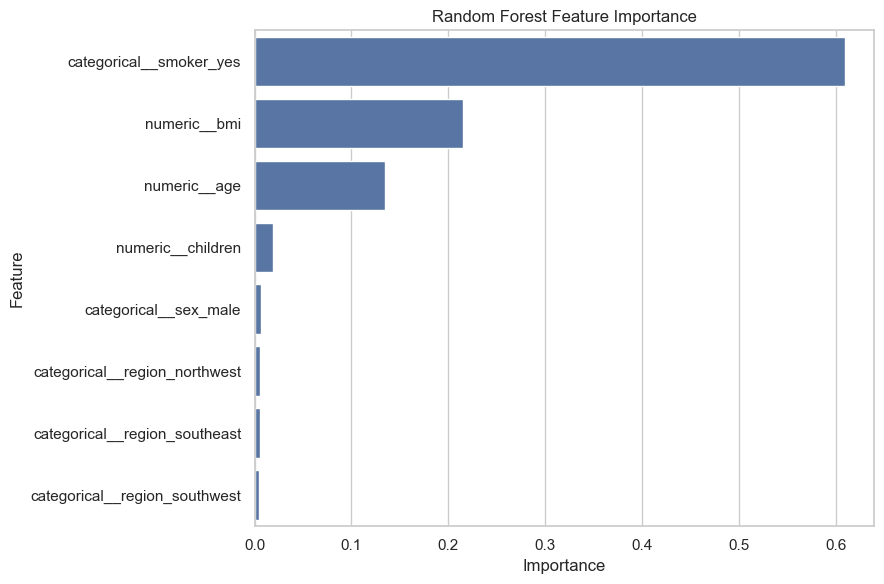

In [20]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Linear Regression Coefficients

In [21]:
# Extract encoded feature names
linear_feature_names = (
    linear_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract coefficients
linear_coefficients = (
    linear_model
    .named_steps["model"]
    .coef_
)

coefficient_df = pd.DataFrame({
    "Feature": linear_feature_names,
    "Coefficient": linear_coefficients
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(coefficient_df)

,Feature,Coefficient,Absolute Coefficient
1,categorical__smoker_yes,"23,651.13","23,651.13"
4,categorical__region_southwest,-809.80,809.80
3,categorical__region_southeast,-657.86,657.86
7,numeric__children,425.28,425.28
2,categorical__region_northwest,-370.68,370.68
6,numeric__bmi,337.09,337.09
5,numeric__age,256.98,256.98
0,categorical__sex_male,-18.59,18.59


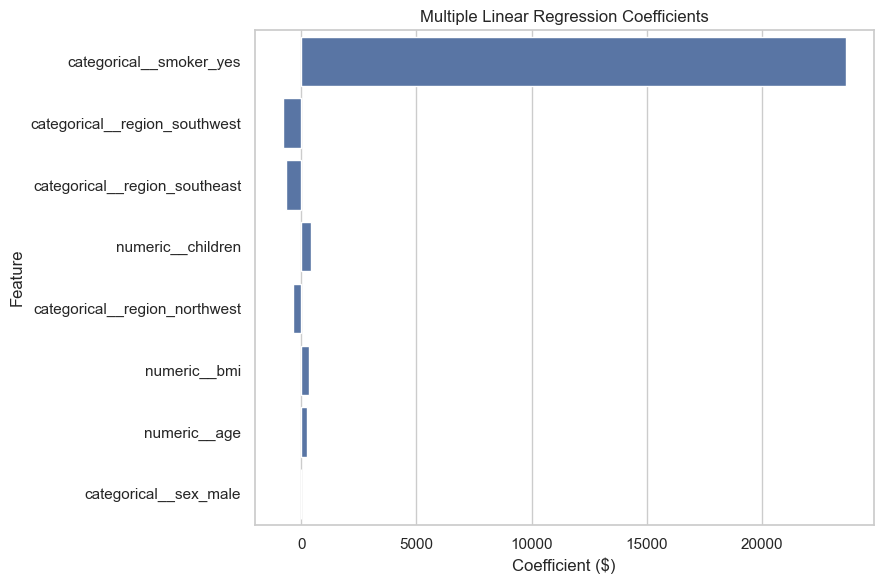

In [22]:
top_coefficients = coefficient_df.head(10).copy()

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Multiple Linear Regression Coefficients")
plt.xlabel("Coefficient ($)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Training vs. Testing Performance

In [23]:
# Training predictions
y_train_pred_linear = linear_model.predict(X_train)
y_train_pred_rf = random_forest_model.predict(X_train)

# Training metrics
linear_train_r2 = r2_score(y_train, y_train_pred_linear)
rf_train_r2 = r2_score(y_train, y_train_pred_rf)

comparison = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Random Forest Regression"
    ],
    "Training R²": [
        linear_train_r2,
        rf_train_r2
    ],
    "Testing R²": [
        linear_r2,
        rf_r2
    ]
})

display(comparison)

,Model,Training R²,Testing R²
0,Multiple Linear Regression,0.74,0.78
1,Random Forest Regression,0.98,0.86
